## A Map of Intracellular Electrophysiology Data on DANDI

I thought it would be a fun exercise to integrate all the open intracellular electrophysiology datasets from the [DANDI archive](https://dandiarchive.org/) into a single dataset, similar to projects in the transcriptomics world like [HYPOMAP](https://www.nature.com/articles/s42255-022-00657-y) and [MapMyCells](https://brain-map.org/bkp/analyze/mapmycells).

Browse the frontend here: https://smestern.com/intraDANDI_explorer/

### TOC

* [1. What is This?](#what-is-this)  
* [2. Examine The Embeddings](#examining-the-embeddings)  
* [3. Is what we are seeing biological differences or a confound?](#is-what-we-are-seeing-biological-differences-or-a-confound-i-am-not-sure)  
    * [3.1. Pulling apart a few technical factors](#pulling-apart-a-few-technical-factors)  
    * [3.2. Can we tell the datasets apart?](#can-we-tell-the-datasets-apart)  
* [4. Interesting landmarks](#interesting-landmarks)  
    * [4.1. The clusters](#the-clusters)  
    * [4.2. The Fast Spikers and Broad Spikers](#the-fast-spikers-and-broad-spikers)  
    * [4.3. The sag islands](#the-sag-islands)  
    * [4.4. The latency corner](#the-latency-corner)  
* [5. The process](#the-process)  
    * [5.1. Getting a consistent protocol](#part-1-getting-a-consistent-protocol)  
    * [5.2. Getting the files through ipfx](#part-2-getting-the-files-through-ipfx)  
    * [5.3. Finding some metadata](#part-3-finding-some-metadata)  
    * [5.4. Building the map](#part-4-building-the-map)  


### What is this?

In this project I extracted features from whole cell patch clamp recordings. Whole-cell patch clamp is a technique where a small pipette is placed next to a single neuron's membrane, then the experimenter applies suction and breaks through the membrane. This makes the pipette continuous with the inside of the cell, allowing experimenters to 'listen' to the inner electrical workings of neurons. From here, neuroscientists can answer many questions about how neurons operate. For example, they might use 'voltage-clamp' (where the neuron's voltage is held at a specified level and membrane currents are recorded) to examine ionic currents. Or they might use 'current-clamp' (where current is applied via the patch pipette and neuron voltage is recorded) to examine how neurons react to changes in current.

In this project, I'm looking at "long pulse" ([see below](#part-1-getting-a-consistent-protocol)) current clamp recordings from cells across the nervous system. The protocol includes both subthreshold and suprathreshold components, allowing researchers to obtain a general profile of how the neuron behaves, similar to how transcriptomics research takes a "snapshot" of a cell's transcriptomic phenotype. Here we use the long pulse to get a "snapshot" of the neuron's electrophysiology, where we can observe things like its spikes, rebounds, and subthreshold oscillations, giving us an electrophysiological fingerprint (like the ephys phenotyping from [Gouwens et al. 2020](https://pubmed.ncbi.nlm.nih.gov/33186530/)). Let's look at some examples:

/tmp/ipykernel_4181196/992569182.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


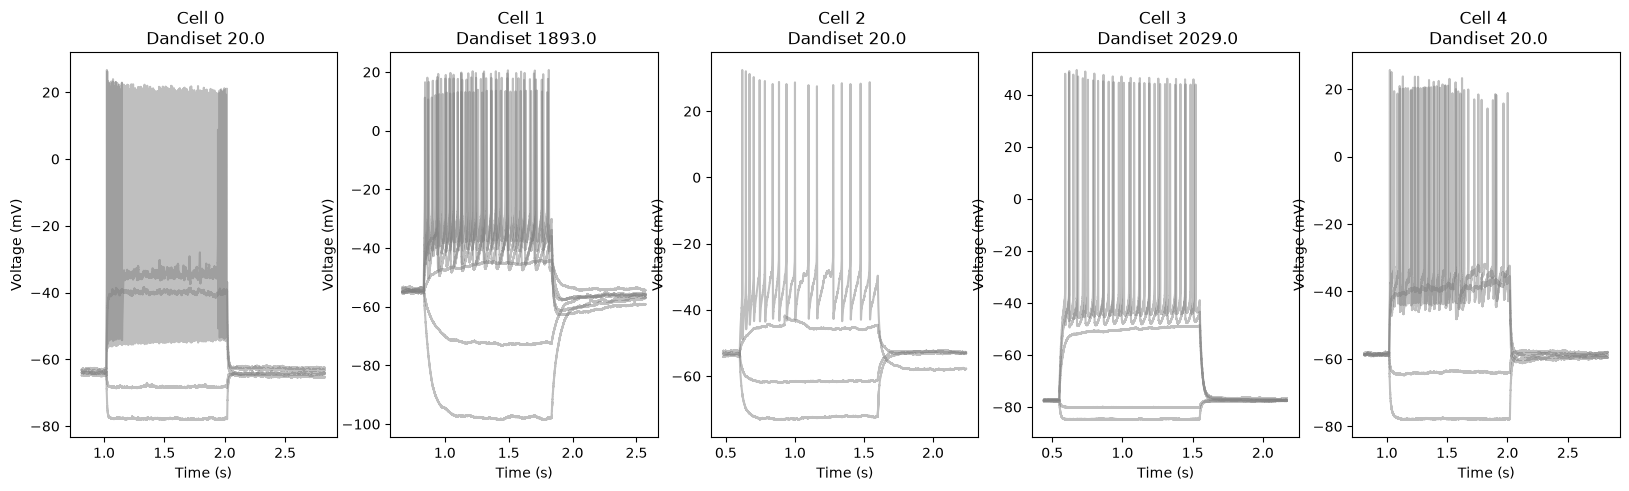

In [1]:
#load the data
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
#compute the kNN of the features used for each cell
from sklearn.neighbors import NearestNeighbors
from sklearn.impute import SimpleImputer
import os
from gigaseal.loadFile import loadNWB
import os
from dandi_scraper.traces import plot_data
from IPython.display import clear_output
data = pd.read_csv('all_new.csv')
#plot a couple feature distributions
#the same 11 features used to build the map (see Part 4)
from dandi_scraper.config import COLS_TO_KEEP
features_used = list(COLS_TO_KEEP)
imputer = SimpleImputer(strategy='mean')
data[features_used] = imputer.fit_transform(data[features_used])
selected_features = ['input_resistance', 'tau',  'ap_1_width_0_long_square', 'sag_nearest_minus_100']
#load the file, point towards your dandi cache
folder = f"/media/inouelinux/sgbackup/"
#grab some random cells to plot later
np.random.seed(40)
random_cells = data.sample(n=5, random_state=1)

fig, axs = plt.subplots(1,5, figsize=(20,5))
for i, (_, cell) in enumerate(random_cells.iterrows()):
    cell_path = cell.loc['specimen_id']
    primairy_cell = plot_data(0, [os.path.join(folder, cell_path)], overwrite=True, save=False, stim_override='')
    plt.close(primairy_cell['fig_trace']); plt.close(primairy_cell['fi_fig'])
    [axs[i].plot(x, y, color='gray', alpha=0.5) for x, y in zip(primairy_cell['sweep_xs'], primairy_cell['sweep_ys'])]
    axs[i].set_title(f"Cell {i} \n Dandiset {cell['dandiset_id']}")
    axs[i].set_xlabel('Time (s)')
    axs[i].set_ylabel('Voltage (mV)')
clear_output()
fig.show()

Here you can see the uniqueness of cell firing patterns. Some cells, like cell 4, show an irregular phenotype, while others, like cell 0, show a regular spiking phenotype. From here, we'll extract features from the traces using the Allen Institute's [Intrinsic Physiology Feature Extractor (IPFX)](https://ipfx.readthedocs.io/en/latest/). We'll extract both spiking and subthreshold features to get a comprehensive "fingerprint" of the neuron. Below we've embedded these features for all ~15,000 cells in the dataset.

## Examining the Embeddings
Lets take a look at the overall embedding of the data.
![alt text](<../figures/blog/2x/Artboard 1@2x.png>)  
Fig 1: UMAP embedding of all 15,869 cells from 52 dandisets. Top left: cells coloured by species. Bottom left: cells coloured by brain region (neocortex and unknown are greyed out so the smaller regions stand out). Right: the six coarse clusters, with three example cells from each cluster (circles mark where each example sits on the map).

As a sanity check, we can look at how features map over a UMAP. Notably, there is a lot of controversy about [interpreting feature distributions on UMAPs](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1011288). However, we are just using it as a general sanity check to ensure the UMAP is embedding logically and not exploiting any bias in the data.

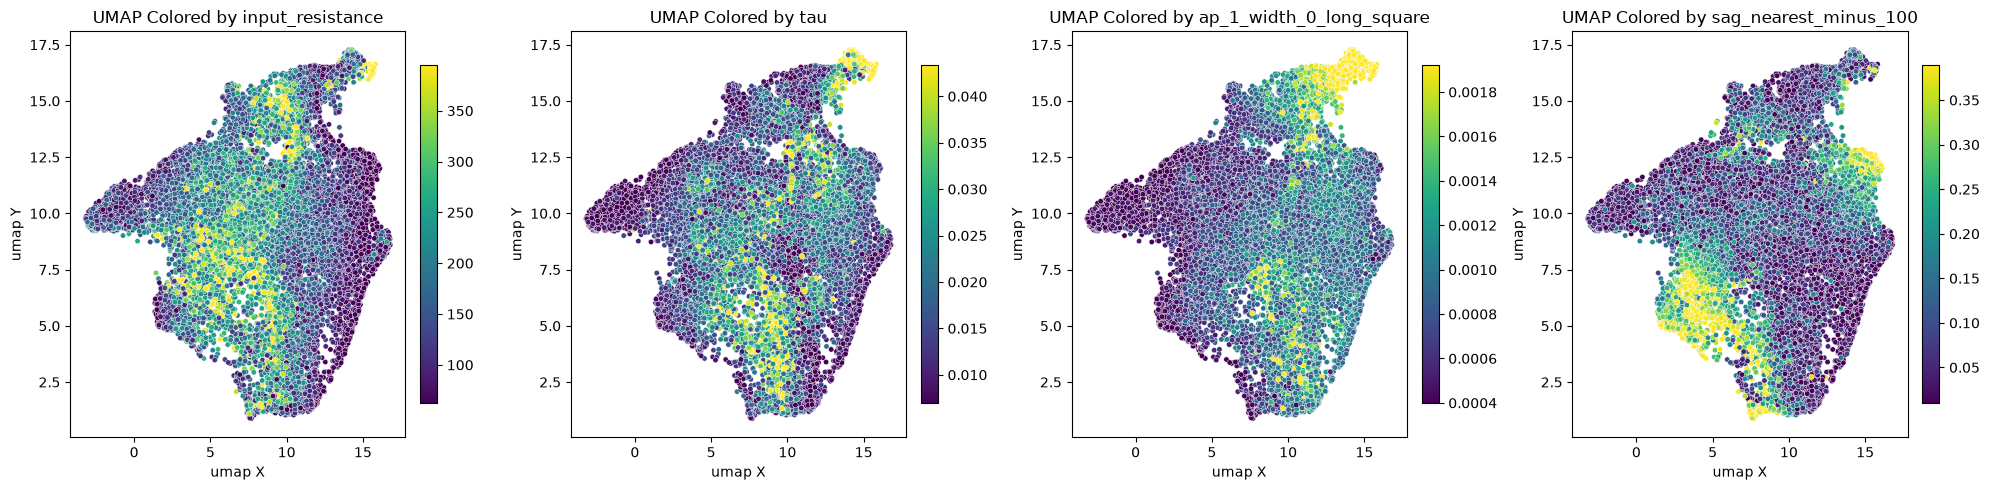

In [2]:
#run a grid of plots of feature distributions on the UMAP
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, feature in enumerate(selected_features):
    row = 1
    col = i % 4
    #ensure to use viridis palette for continuous features
    #clip the feature to the 5th and 95th percentile for better visualization
    clipped_feature = data[feature].clip(lower=data[feature].quantile(0.05), upper=data[feature].quantile(0.95))
    sns.scatterplot(data=data, x='umap X', y='umap Y', hue=clipped_feature, palette='viridis', s=15, ax=axes[col])
    axes[col].set_title(f'UMAP Colored by {feature}')
    #remove the legend for clarity
    axes[col].legend_.remove()
    #add a colorbar
    norm = plt.Normalize(vmin=clipped_feature.min(), vmax=clipped_feature.max())
    sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
    sm.set_array([])
    fig.colorbar(sm, ax=axes[col], orientation='vertical', fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
    

Here, we can see the UMAP is clustering feature values together in a somewhat coherent manner. Promisingly (to me) is the mapping -x to +x mapping of action potential width, a common feature for very rudimentary electrophysiological cell typing in the cortical regions (https://www.nature.com/articles/s41593-019-0417-0). 

From here, we can also look at cells' K-NN neighbours in the dataset, a sanity checks to see if the cells match qualitatively across datasets. We would expect cells with similar electrophysiology phenotypes to group together

![alt text](../figures/blog/cluster_examples_grid_preview.png)

The results are interesting. Qualitatively, cells with similar ephys fingerprints do seem to be neighbours (regardless of species). 

# Is what we are seeing biological differences or a confound? (I am not sure)

Above I presented the idea that the embeddings do show some coherence in feature grouping. However, one may note that both species and region remain separated in the embedding. This presents an interesting potential biological difference that we could investigate. However, this observation comes with a few caveats:
- Most regions only have one dandiset to represent them (i.e. a single origin lab)
- Most species also have a single origin lab (save for the Allen Inst.), or also differ in region from the remaining data
- Recording conditions differ between many dandisets: temperature, sampling rate, and even the long-pulse protocol itself (step duration and step size)

Given that ephys lab protocols (solutions, temperature, time of slicing, etc.) can drastically alter recorded ephys features, and that these protocols vary slightly (or drastically) between labs, it becomes tricky to separate real biological differences from 'batch effects' between labs.

First we can look at how the raw features differ between dandisets, regions, and species:  
![](../figures/umap_workup_tf20/06_dandiset_feature_medians.png)  
Fig 2: Median value of each feature per dandiset, scaled so that 0 is the population median (red = higher, blue = lower). Label colour is the lab the dandiset came from.

Here we can see that features are generally skewed between datasets. For example, dandiset "000148" features recordings from spinal cord interneurons in the mouse. We can see the median input resistance (Rin) and time constant (tau) are quite a bit higher than the other dandisets. This is consistent with reported high values in mouse spinal cord interneurons: [https://neuroelectro.org/neuron/175.html](https://neuroelectro.org/neuron/175.html). So it's possible that this is a real biological signal; however, without an alternate dandiset in the spinal cord, we cannot fully make that conclusion.  
Another example is the high "sag" (see below) reported in the pigtail macaque. This is consistent with reported values: https://www.cell.com/cell/fulltext/S0092-8674(26)01278-X (in fact I believe these datasets are part of this publication). These datasets originate from the Allen Inst., so comparing between Allen Inst. datasets could be considered valid, in which case this is likely a real biological observation.  

The best check is to look at how much of each feature's variance can be explained by species, then region, then dandiset:
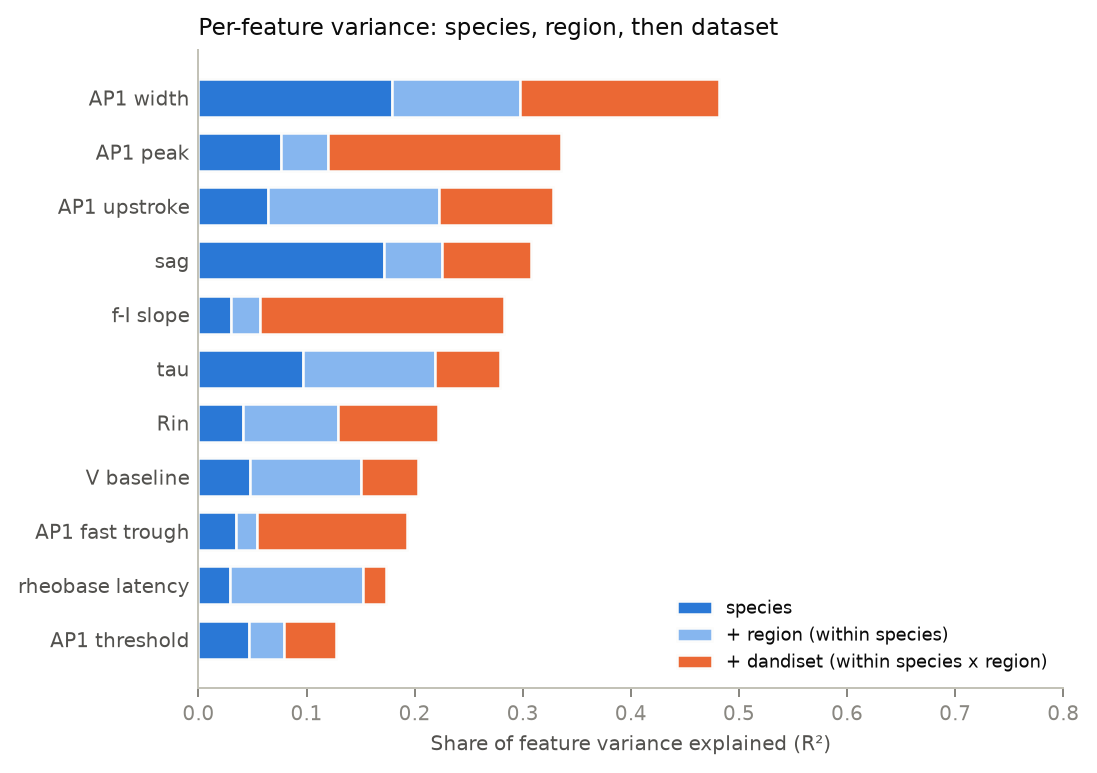  
Fig 3: How much of each feature's variance is explained by where the cell came from. Dark blue is the share explained by species alone, light blue is the extra share explained by adding region (within species), and orange is the extra share explained by adding dandiset (within species x region). The bars stack, so the full length of each bar is the share explained by dandiset alone. Everything left over (the gap to 1.0) is variation between cells within a dandiset. Computed as a simple between-group R² on the same scaled features fed into the UMAP.

A few things stand out to me here. For every feature, at least half of the variance is *not* explained by any of these labels. It sits between cells within the same dandiset, which is what we would hope for if the map is mostly capturing cell types.

The features with the largest dandiset share (beyond species and region) are f-I slope (0.23), AP peak (0.22), AP width (0.18) and AP fast trough (0.14). These are mostly spike shape features, which are exactly the ones we would expect to be sensitive to recording temperature and acquisition settings. The f-I slope I suspect is partially a protocol thing, as the datasets use different step sizes (from 2 pA up to 50 pA) and step durations (0.5 to 1 s). On the other hand, the passive features (Rin, tau, V baseline) and first spike latency are mostly explained by species and region, with only a small extra dandiset term. Sag has the largest species term of any feature (~0.17), which lines up with the macaque sag story above.

There are two big caveats to reading this plot, though:
- Since most regions (and many species) only come from a single dandiset, the blue bars are not clean 'biology' either. If a region only has one dataset, any lab effect gets credited to the region first. So I would read the blue bars as an upper bound on the biology, and the orange bars as a lower bound on the lab effect.
- A 'dandiset effect' is not necessarily technical. Labs target different cells. For example, dandiset 000020 is enriched for GABAergic cells (~25% fast spikers) whereas 001455 has essentially none. Fast spikers peak ~14-23 mV below the broad spikers in every lab, so some of the orange in AP peak and width is just which cells each lab chose to patch.

### Pulling apart a few technical factors

To get a better feel for the orange bars, I checked a few of the technical suspects directly:

- Temperature: The Tolias lab has two mouse neocortex dandisets, 000008 (room temp) and 000035 (recorded warmer). Same lab, species, and region, which makes for a nice comparison. The median AP width drops from ~1.16 ms to ~0.68 ms (roughly 40% narrower) and the AP peak drops by ~10 mV in the warmer set, while tau and threshold barely move. This fits with the temperature effect on [ion channel kinetics](https://link.springer.com/article/10.1007/BF00584655) mentioned below.
- Sampling rate: Most of the Allen data is sampled at 50 kHz, whereas many of the other labs (including the spinal cord sets) sampled at 10 kHz. To test this, I took Allen cells and degraded them down to 10 kHz, then re-ran the feature extraction. This only explained ~10% of the AP width gap between the 10 and 50 kHz datasets, and almost none of the AP peak gap. AP upstroke is the most sensitive (about a third of the gap, more with heavier filtering). The passive features did not change at all. So sampling rate is a factor for upstroke, but it does not explain most of the differences.
- Protocol: For about half the cells, the rheobase sweep contains a single spike, so the 'firing rate at rheobase' is really just 1/(step duration). Coarser current steps also overshoot rheobase. Because of this I swapped rheobase firing rate out for the f-I slope.

![](../figures/downsampling_test/02_effect_vs_real_gap.png)  
Fig 4: The effect of degrading the same 50 kHz Allen cells (blue bars) compared to the real difference between the 10 kHz and 50 kHz datasets (orange line). For width and peak, downsampling barely closes the gap.

### Can we tell the datasets apart?

Another way to ask the question is: if I hand a classifier cells from two dandisets, can it tell which is which? (0.5 = indistinguishable, 1.0 = perfectly separable.)

![](../figures/umap_workup_tf20/05_pair_auc_by_kind.png)  
Fig 5: Pairwise classifier accuracy (AUC) between every pair of dandisets, split by how similar the pair is on paper.

Dandisets from the same species and region but a different lab are almost perfectly separable (median AUC 0.99), just as separable as dandisets from different species. Dandisets from the same lab, species and region are still distinguishable (median 0.83), but much less so. To me, this suggests that the lab is a major factor. However, the many Allen human datasets mix together well in the UMAP, so when the protocol is standardized, datasets do overlap. Dandiset 001538 (mouse striatum) forms its own island. I think this one is real biology: it is the only striatal dataset, and the cells look like textbook spiny projection neurons (very hyperpolarized baseline, low Rin, almost no sag, long latency to first spike).

I also tried a whole bunch of UMAP settings and feature subsets to see if I could get the datasets to mix better. Unfortunately I really couldn't find one with a good balance. The only thing that removes the dataset structure is centring every dandiset on itself, but that also wipes out the real differences (e.g. the striatal island and the primate sag). I also attempted my PatchOTDA technique, this did work well for integration, but I worried it presented the same problem. So, for now, I chose not to correct for anything.

So is it biology or a confound? I think it is likely a bit of both. The big features (fast vs broad spikers, sag, latency) seem to hold up across labs. But I would be very cautious about reading species or region differences off the map when they come from a single lab. As more labs deposit data covering the same regions, we should be able to tease these apart.

# Interesting landmarks

## The clusters

To get a rough overview of the map, I split the cells into clusters. Here, I used a Gaussian mixture model (GMM) on the same scaled features used to build the UMAP (not on the UMAP coordinates themselves). The clustering is done in two tiers: first the cells are split into 6 coarse clusters, then each coarse cluster is split into up to 5 fine clusters (30 in total). I'll mostly stick to the 6 coarse clusters here (Fig 1, right). The number of clusters is a setting I picked, so I would not read too much into the exact boundaries.

![](../figures/blog/cluster_feature_heatmap_preview.png)  
Fig 6: Median value of each feature per coarse cluster. The number in each box is the median, and the colour shows how far that median sits from the population median (in IQRs; red = higher, blue = lower).

A rough tour of the clusters:
- Cluster 1 - "Regular spiking-ish" (n=5,921): The largest cluster. Broad, tall spikes (~0.95 ms wide, ~44 mV peak), a lower input resistance and a shallow f-I slope. This is roughly what I would expect from pyramidal (excitatory) neurons, and only ~1% of its cells are fast spikers. It also picks up most of the amygdala (75%) and striatum (80%) cells, and most of the Tolias lab cells (74%).
- Cluster 2 - "Regular spiking interneurons" (I think) (n=4,112): Narrower spikes (~0.66 ms), a higher input resistance (~220 MΩ) and a steeper f-I slope than cluster 1. Over half of this cluster comes from dandiset 000020, the Allen Inst. mouse visual cortex Patch-seq set, which focuses on GABAergic cells. So I suspect this cluster is mostly non-fast-spiking interneurons.
- Cluster 3 - "Longer latency" (n=2,198): This cluster is defined almost entirely by its long latency to the first spike (median ~570 ms, vs ~60-140 ms for the other clusters). This is the latency corner discussed below. About half of these cells come from dandisets with an "Unknown" region (mostly Allen Inst. sets), and it also takes about half of the brainstem cells.
- Cluster 4 - "Sag" (n=1,890): High sag (median ratio of 0.34, vs ~0.04-0.09 for the other clusters) and a slightly more depolarized baseline. This is the primate cluster: 45% human and ~38% non-human primate, vs only 17% mouse. This lines up with sag having the largest species term in Fig 3.
- Cluster 5 - "Fast burst" (n=994): Small, slow spikes (upstroke ~120 V/s, about half that of the other clusters, ~17 mV peak, ~1.4 ms wide), along with a high input resistance and slow tau. This cluster collects most of the non-cortical cells: 92% of the spinal cord cells, 64% of the basal forebrain cells, and about half of the pallidum cells.
- Cluster 6 - "Fast spikers" (n=754): Narrow spikes (~0.42 ms), a fast tau (~7 ms), low input resistance, and a very steep f-I slope (~0.8 Hz/pA). 87% of these cells pass the usual fast spiking cutoff (narrow width and a low upstroke:downstroke ratio). These are likely Pv-like interneurons.

![](../figures/blog/region_by_cluster_preview.png)  
Fig 7: The share of each brain region's cells that falls in each cluster.

Of course, the caveats from above apply here too, and a couple of the clusters show it pretty clearly:
- Cluster 6 is 94% one dandiset (000020). There are plenty of fast spikers elsewhere in the data, but they mostly don't end up here. Of the ~700 primate fast spikers, only 22 land in cluster 6; most of them (~390) land in the sag cluster (4) instead. Even about a third of 000020's own fast spikers land in cluster 2. The primate fast spikers have a lot more sag than the mouse ones (median sag ratio of 0.30 vs 0.05). Since 93% of these primate cells also come from the Allen Inst. (the same lab as 000020), I lean towards this being a real species difference. However, I have not looked into it further.
- Cluster 5 is enriched for the 10 kHz datasets. A quarter of its cells were sampled at 10 kHz, compared to ~5% of the whole dataset. Since AP upstroke is the feature most affected by sampling rate (see above), some of this cluster is likely technical. That said, the 50 kHz cells in this cluster also have slow upstrokes (median ~130 V/s), so it is not only a sampling effect.

So, I would treat the clusters as a handy way to navigate the map, rather than as cell types. With that in mind, let's look at a few landmarks in more detail.

## The Fast Spikers and Broad Spikers:

As noted above, spike width is a common metric for rapid, rough cell typing of cortical neurons (particularly in the extracellular electrophysiology world). The fast spikers are generally thought to be putative inhibitory neurons (likely Pv cells), whereas the broad spikers are thought to be putative excitatory pyramidal neurons. We now know that this distinction is not as clear-cut, as not all inhibitory neurons show "fast spikes" (see [Gouwens et al. 2019](https://www.nature.com/articles/s41593-019-0417-0)), and non-cortical regions do not have such clear cell-types (save for maybe the hippocampus). Regardless, as a first pass, looking at the distinction between the narrow and broad spikers seems like a good idea. The UMAP shows a pretty clear separation of spike width along the x-axis

/tmp/ipykernel_4181196/3926691423.py:51: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


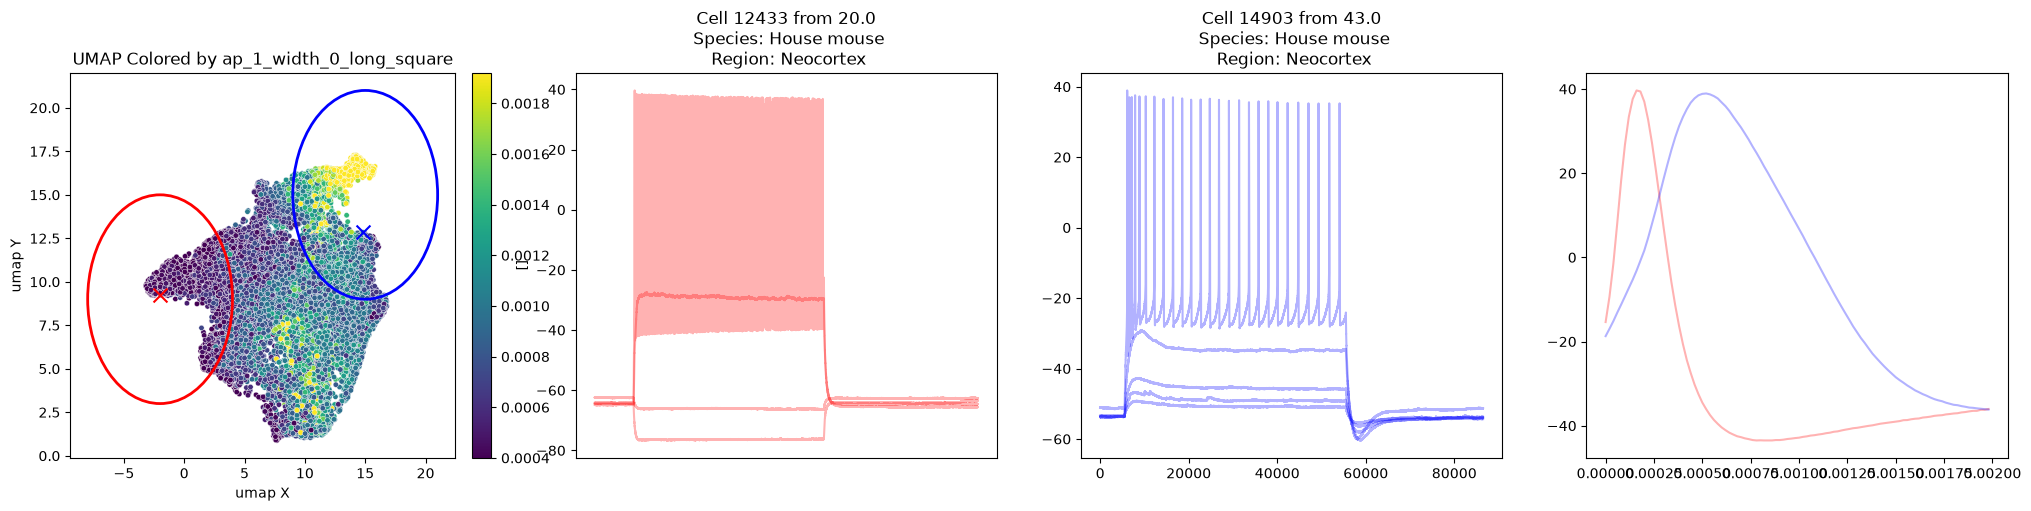

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(25,5))
feature = "ap_1_width_0_long_square"
clipped_feature = data[feature].clip(lower=data[feature].quantile(0.05), upper=data[feature].quantile(0.95))
sns.scatterplot(data=data, x='umap X', y='umap Y', hue=clipped_feature, palette='viridis', s=15, ax=ax[0])
ax[0].set_title(f'UMAP Colored by {feature}')
#remove the legend for clarity
ax[0].legend_.remove()
#add a colorbar
norm = plt.Normalize(vmin=clipped_feature.min(), vmax=clipped_feature.max())
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax[0], orientation='vertical', fraction=0.046, pad=0.04)
#draw circles around the sag sections
circle1 = plt.Circle((-2, 9), 6, color='red', fill=False, linewidth=2)
ax[0].add_patch(circle1)
circle2 = plt.Circle((15, 15), 6, color='blue', fill=False, linewidth=2)
ax[0].add_patch(circle2)
#pick out 2 cells closest to the center of the circles
center1 = np.array([-2, 9])
center2 = np.array([15, 14])
umap_coords = data[['umap X', 'umap Y']].values
distances1 = np.linalg.norm(umap_coords - center1, axis=1)
closest_cell1 = np.argmin(distances1)
distances2 = np.linalg.norm(umap_coords - center2, axis=1)
closest_cell2 = np.argmin(distances2)
print(f"Closest cell to circle 1: {closest_cell1}, width value: {data.loc[closest_cell1, feature]}")
print(f"Closest cell to circle 2: {closest_cell2}, width value: {data.loc[closest_cell2, feature]}")
#put 'x' markers on the closest cells
ax[0].scatter(data.loc[closest_cell1, 'umap X'], data.loc[closest_cell1, 'umap Y'], color='red', s=100, marker='x')
ax[0].scatter(data.loc[closest_cell2, 'umap X'], data.loc[closest_cell2, 'umap Y'], color='blue', s=100, marker='x')


for i, cell_in in enumerate([closest_cell1, closest_cell2]):
    cell_path = data.loc[cell_in, 'specimen_id']
    cell_region = data.loc[cell_in, 'brain_region']
    cell_species = data.loc[cell_in, 'species']
    primairy_cell = plot_data(0, [os.path.join(folder, cell_path)], overwrite=True, save=False, stim_override='')
    for sweep_x, sweep_y in zip(primairy_cell['sweep_xs'], primairy_cell['sweep_ys']):
        ax[i+1].plot(sweep_y, color='r' if i==0 else 'b', alpha=0.3, )
        if np.any(sweep_y>-20):
            idx_thres = np.where(sweep_y>-20)[0][0]
            ax[-1].plot(sweep_x[idx_thres:idx_thres+100] - sweep_x[idx_thres], sweep_y[idx_thres:idx_thres+100], color='r' if i==0 else 'b', alpha=0.3, )
            break
    ax[i+1].set_title(f'Cell {cell_in} from {data.loc[cell_in, "dandiset_id"]}\n Species: {cell_species}\n Region: {cell_region}')
    plt.close(primairy_cell['fig_trace']); plt.close(primairy_cell['fi_fig'])
ax[1].set_ylabel([])
ax[1].set_xticks([])


clear_output()
fig.show()



## The sag islands:

There are two distinct islands in the UMAP embedding with a large measured "Sag". Sag in this case refers to the deflection present in the voltage when a cell is stimulated with a hyperpolarizing pulse. 

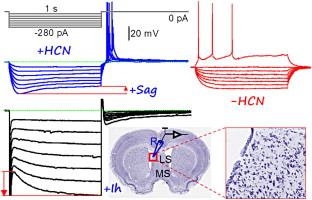

Image: A example of an HCN driven 'sag' from: https://doi.org/10.1016/j.neuropharm.2014.02.012


You may see a cell with sag described as having a h-current (or Ih), and this h-current is [thought to be driven by HCN channels](https://www.cell.com/neuron/fulltext/S0896-6273(18)30900-0). H-current bestows a number of different computation properites on neurons and expression differs across species and age (check out: [here](https://www.cell.com/neuron/fulltext/S0896-6273(18)30900-0), [or here](https://academic.oup.com/cercor/article/31/2/845/5927870?login=true)). Here sag is expressed as a ratio between steady state and absolutle deflection, you may see papers report absoulte or relative deflection in mV instead.

/tmp/ipykernel_4181196/3934691761.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


Closest cell to circle 1: 7744, sag value: 0.758311927318573
Closest cell to circle 2: 6378, sag value: 0.4704836010932922


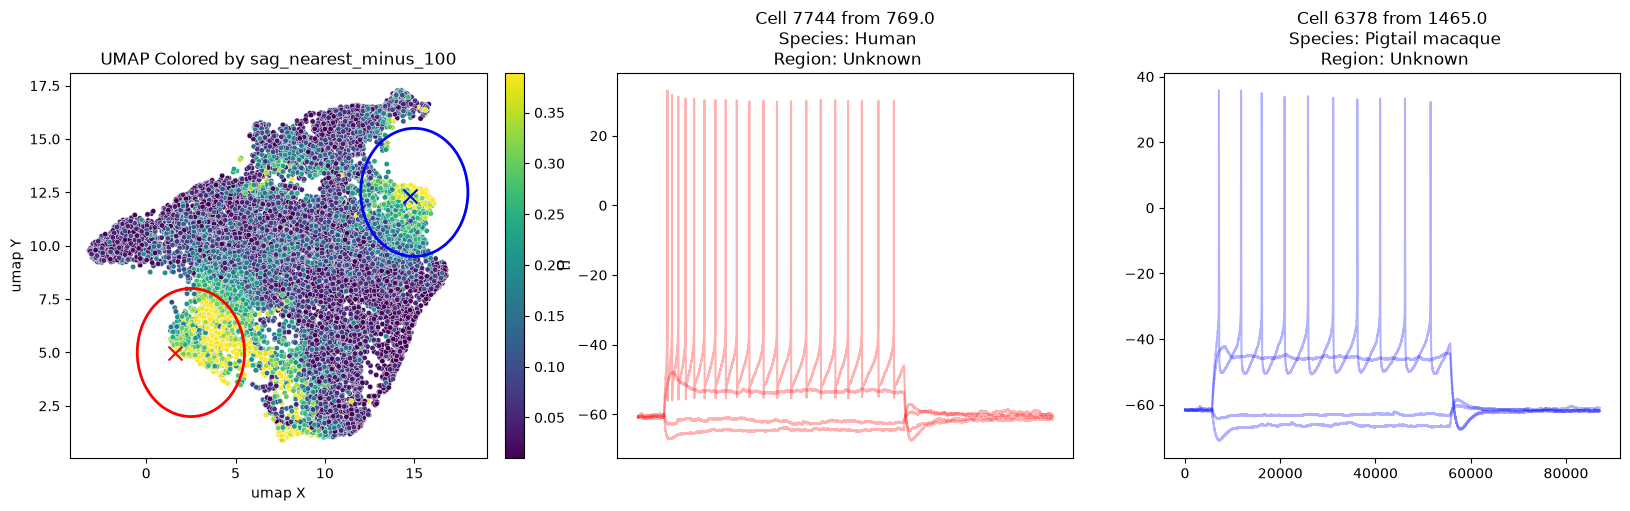

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20,5))
feature = "sag_nearest_minus_100"
clipped_feature = data[feature].clip(lower=data[feature].quantile(0.05), upper=data[feature].quantile(0.95))
sns.scatterplot(data=data, x='umap X', y='umap Y', hue=clipped_feature, palette='viridis', s=15, ax=ax[0])
ax[0].set_title(f'UMAP Colored by {feature}')
#remove the legend for clarity
ax[0].legend_.remove()
#add a colorbar
norm = plt.Normalize(vmin=clipped_feature.min(), vmax=clipped_feature.max())
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax[0], orientation='vertical', fraction=0.046, pad=0.04)
#draw circles around the sag sections
circle1 = plt.Circle((2.5, 5.0), 3, color='red', fill=False, linewidth=2)
ax[0].add_patch(circle1)
circle2 = plt.Circle((15.0, 12.5), 3, color='blue', fill=False, linewidth=2)
ax[0].add_patch(circle2)
#pick out 2 cells closest to the center of the circles
center1 = np.array([2.5, 5.0])
center2 = np.array([13.0, 12.5])
umap_coords = data[['umap X', 'umap Y']].values
#get cells within the circles, then pick the one with highest sag value
distances1 = np.linalg.norm(umap_coords - center1, axis=1)
#get indices of cells within the circle
within_circle1 = np.where(distances1 < 3)[0]
#pick the cell with the highest sag value
closest_cell1 = within_circle1[np.argsort(data.loc[within_circle1, feature].values)[-5]]
distances2 = np.linalg.norm(umap_coords - center2, axis=1)
#get indices of cells within the circle
within_circle2 = np.where(distances2 < 2)[0]
#pick the cell with the highest sag value
closest_cell2 = within_circle2[np.argsort(data.loc[within_circle2, feature].values)[-4]]

#put 'x' markers on the closest cells
ax[0].scatter(data.loc[closest_cell1, 'umap X'], data.loc[closest_cell1, 'umap Y'], color='red', s=100, marker='x')
ax[0].scatter(data.loc[closest_cell2, 'umap X'], data.loc[closest_cell2, 'umap Y'], color='blue', s=100, marker='x')
for i, cell_in in enumerate([closest_cell1, closest_cell2]):
    cell_path = data.loc[cell_in, 'specimen_id']
    cell_region = data.loc[cell_in, 'brain_region']
    cell_species = data.loc[cell_in, 'species']
    primairy_cell = plot_data(0, [os.path.join(folder, cell_path)],target_amps=[-100, 0, 10, 100, 200] , overwrite=True, save=False, stim_override='')
    for sweep_y in primairy_cell['sweep_ys']:
        ax[i+1].plot(sweep_y, color='r' if i==0 else 'b', alpha=0.3, )
    ax[i+1].set_title(f'Cell {cell_in} from {data.loc[cell_in, "dandiset_id"]}\n Species: {cell_species}\n Region: {cell_region}')
    plt.close(primairy_cell['fig_trace']); plt.close(primairy_cell['fi_fig'])
ax[1].set_ylabel([])
ax[1].set_xticks([])
clear_output()
#label the sag on cell 1
ax[1].annotate('Sag', xy=(9.e3, -80), xytext=(9.e3,-70),
            arrowprops=dict(facecolor='black', shrink=0.05))

fig.show()
print(f"Closest cell to circle 1: {closest_cell1}, sag value: {data.loc[closest_cell1, feature]}")
print(f"Closest cell to circle 2: {closest_cell2}, sag value: {data.loc[closest_cell2, feature]}")

## The latency corner:

The feature 'latency_0_long_square' refers to the latency to the first spike. A cell with a long latency may have distinct computational properties that regulate its overall excitability. We can see that cells with a long latency cluster into the northeast corner of the UMAP space.

/tmp/ipykernel_4181196/1754571969.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


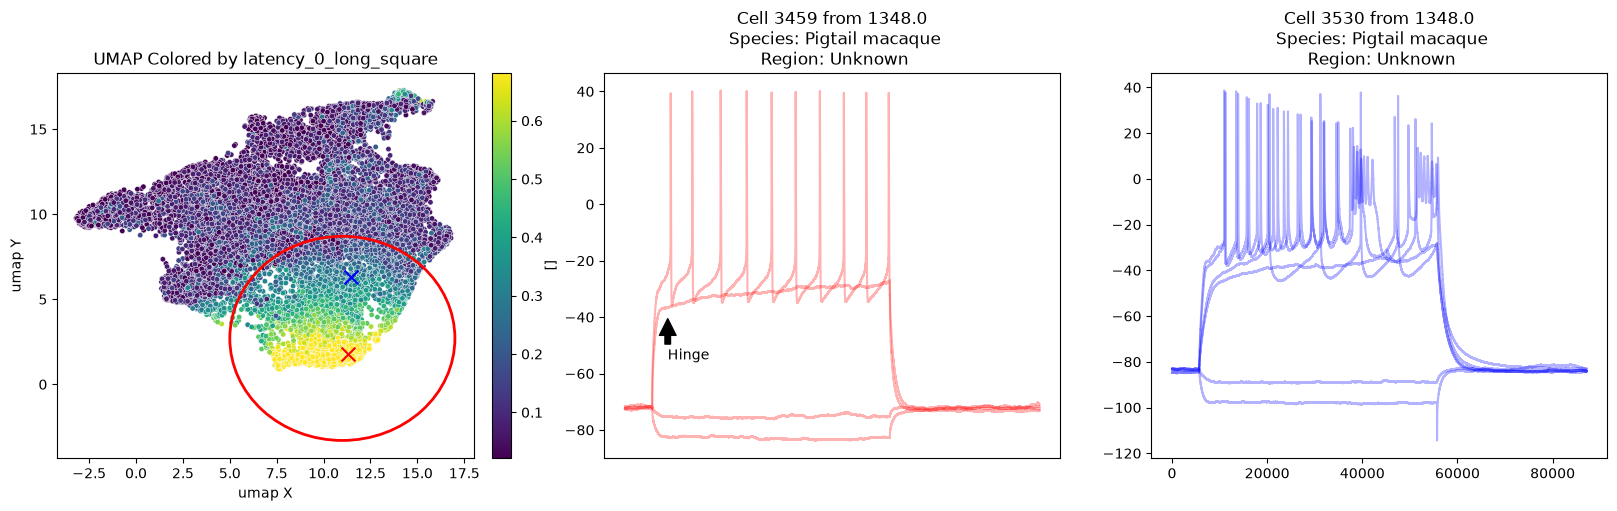

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(20,5))
feature = "latency_0_long_square"
clipped_feature = data[feature].clip(lower=data[feature].quantile(0.05), upper=data[feature].quantile(0.95))
sns.scatterplot(data=data, x='umap X', y='umap Y', hue=clipped_feature, palette='viridis', s=15, ax=ax[0])
ax[0].set_title(f'UMAP Colored by {feature}')
#remove the legend for clarity
ax[0].legend_.remove()
#add a colorbar
norm = plt.Normalize(vmin=clipped_feature.min(), vmax=clipped_feature.max())
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax[0], orientation='vertical', fraction=0.046, pad=0.04)
#draw circles around the sag sections
circle1 = plt.Circle((11, 2.7), 6, color='red', fill=False, linewidth=2)
ax[0].add_patch(circle1)

#good examples
example1 = "001348/sub-1376316470/sub-1376316470_ses-1379003900_icephys.nwb"
example2 = "001348/sub-1347447837/sub-1347447837_ses-1363888215_icephys.nwb"
idx_closest_cell = data.index[data['specimen_id'] == example1].tolist()[0]
closest_cell1 = idx_closest_cell
idx_closest_cell2 = data.index[data['specimen_id'] == example2].tolist()[0]
closest_cell2 = idx_closest_cell2
print(f"Closest cell to circle 1: {closest_cell1}, latency value: {data.loc[closest_cell1, feature]}")
print(f"Closest cell to circle 2: {closest_cell2}, latency value: {data.loc[closest_cell2, feature]}")
#put 'x' markers on the closest cells
ax[0].scatter(data.loc[closest_cell1, 'umap X'], data.loc[closest_cell1, 'umap Y'], color='red', s=100, marker='x')
ax[0].scatter(data.loc[closest_cell2, 'umap X'], data.loc[closest_cell2, 'umap Y'], color='blue', s=100, marker='x')
for i, cell_in in enumerate([closest_cell1, closest_cell2]):
    cell_path = data.loc[cell_in, 'specimen_id']
    cell_region = data.loc[cell_in, 'brain_region']
    cell_species = data.loc[cell_in, 'species']
    primairy_cell = plot_data(0, [os.path.join(folder, cell_path)], overwrite=True, save=False, stim_override='')
    for sweep_y in primairy_cell['sweep_ys']:
        ax[i+1].plot(sweep_y, color='r' if i==0 else 'b', alpha=0.3, )
    ax[i+1].set_title(f'Cell {cell_in} from {data.loc[cell_in, "dandiset_id"]}\n Species: {cell_species}\n Region: {cell_region}')
    plt.close(primairy_cell['fig_trace']); plt.close(primairy_cell['fi_fig'])
ax[1].set_ylabel([])
ax[1].set_xticks([])
#label the hinge on cell 1
ax[1].annotate('Hinge', xy=(9.e3, -40), xytext=(9.e3,-55),
            arrowprops=dict(facecolor='black', shrink=0.05))

clear_output()
fig.show()

Here are two cells with high latency values. The waveforms of the cells show a characteristic 'shoulder' or 'hinge' that is indicative of an A-type current. In my primary brain region of study (the paraventricular nucleus [PVN] of the hypothalamus), we see a lot of [A-type current](https://doi.org/10.1111/j.1469-7793.2000.t01-1-00193) in the neuroendocrine magnocellular neurons. Critically, this a-type current is an important regulator of cellular excitability, with the a-type currents being a target of [NMDA-driven modulation in magnocellular neurons](https://physoc.onlinelibrary.wiley.com/doi/full/10.1113/jphysiol.2014.270793). Its really cool to see it here too!

# The process

***NOTE**: Most of this code was originally written before the various updates to the NWB standard and the package `ipfx`. Many of the problems discussed below are now fixed through various QoL updates. Since then, the extraction code has also moved into my patch-clamp package `gigaseal` (`gigaseal.database.protocol_detect` and `gigaseal.database.long_square`), and the snippets below are the current versions.

## Part 1: Getting a consistent protocol

The first step in collating the data is finding some common features to analyze. With this in mind, I had to choose a common protocol for extracting features. In this case, I chose to extract features from the "long-pulse" current-clamp stimulation protocol. A "long-pulse" protocol is a semi-standard protocol used by patch-clampers to characterize fundamental intrinsic properties of neurons. All of the above voltage traces come from long-pulse protocols. In most cases, the protocol consists of a baseline state, and then a 'long' (typically 0.7 - 2s) epoch of current stimulation. For each sweep of stimulation, the applied current is incremented, typically ranging from -100 to 100+ pA. 


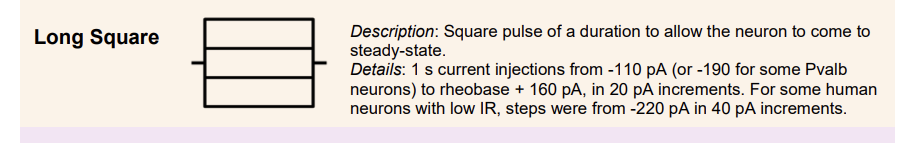  
IMAGE: An example long pulse protocol from the [allen cell types of database](https://celltypes.brain-map.org/). 

However, I ran into a problem. Many of the datasets used did not have an explicitly labelled 'long-pulse'. As such, we had to figure out which sweeps in each dataset were the 'long-pulse' ones. I tried several methods to easily detect long-pulse sweeps, including machine learning techniques. In the end, I relied on simple conditional programming to filter out the long pulse. 

My first version treated any change in the command current as a step edge. This broke on datasets where the command carries line noise, since every sample becomes an 'edge'. The current version finds the step edges against a robust estimate of the noise floor, then checks that the step is flat (not a ramp) and that the command returns to its pre-step baseline (allowing for a holding current, rather than requiring the command to start and end at exactly 0). The code looks like this:

In [6]:
def find_step_transitions(i, noise_k=8.0, abs_floor_frac=0.005, min_gap=5):
    #find square-step edges in a (possibly noisy) command waveform.
    #threshold the first difference against a robust estimate of the noise floor (MAD of the diff),
    #and collapse each ramped transition (which spans several samples) into a single index
    i = np.asarray(i, dtype=float)
    di = np.diff(i)
    if di.size == 0:
        return np.array([], dtype=int), 0.0
    med = np.median(di)
    sigma = 1.4826 * np.median(np.abs(di - med))
    # absolute floor keeps the threshold > 0 on perfectly clean signals
    rng = float(np.nanmax(i) - np.nanmin(i))
    thr = max(noise_k * sigma, max(abs_floor_frac * rng, 1e-9))
    idx = np.flatnonzero(np.abs(di) > thr)
    if idx.size == 0:
        return idx, thr
    # collapse runs of consecutive indices (a single ramped edge) into one
    groups = np.split(idx, np.flatnonzero(np.diff(idx) > min_gap) + 1)
    return np.array([g[0] for g in groups], dtype=int), thr


def match_long_square_protocol(i, t, start_idx, end_idx):
    #here we will do some analysis to determine if the stimulus is a long square
    i = np.asarray(i, dtype=float)
    di_idx, thr = find_step_transitions(i)
    if len(di_idx) < 2:
        #zero or one transition -> not a (returning) square step
        return None

    # A long square holds a flat step and then returns to its pre-step baseline.
    # We compare robust (median) levels rather than requiring the command to
    # start/end at exactly 0, because real recordings carry a holding current
    # and line noise means no sample is ever exactly the baseline value.
    pre = i[:start_idx]
    post = i[end_idx + 1:]
    step = i[start_idx:end_idx + 1]
    if len(pre) == 0 or len(post) == 0 or len(step) == 0:
        return None
    base_pre, base_post, step_level = np.median(pre), np.median(post), np.median(step)
    amp = step_level - base_pre
    if abs(amp) < max(thr, 1e-9):
        #no real step relative to baseline
        return None

    # Reject ramps: a square step is flat, so a straight-line fit across the
    # step region must not drift by a meaningful fraction of the step height.
    x_step = t[start_idx:end_idx + 1]
    if len(x_step) > 2:
        slope, intercept, r_value, p_value, std_err = scipy.stats.linregress(x_step, step)
        if abs(slope * (x_step[-1] - x_step[0])) > 0.3 * abs(amp):
            return None

    # The command must return to (near) its pre-step baseline after the step.
    if abs(base_post - base_pre) > 0.5 * abs(amp):
        return None

    return "Long Square"

Two more problems came up as I added more dandisets. First, many files contain more than one long-pulse run (for example, the hyperpolarizing and depolarizing steps run as separate protocols, or a repeat of the protocol later in the recording). Now, the sweeps that pass are grouped into runs by their step duration, and one run is picked per cell. The ranking prefers a step duration closest to 1 s, then a run with both hyperpolarizing and depolarizing steps (that actually reaches spiking voltages), then the earliest run in the recording (most likely to be at baseline), and finally the run with the most sweeps.

Second, some datasets store the whole protocol as a single long sweep. For example, dandiset 001454 records each cell as one ~70 s sweep with a 0.5 s step every 2 s. These are now detected and split into one sweep per step before the matching above.

## Part 2: Getting the files through ipfx

The next step was processing all the files using a consistent method. For the electrophysiological feature extraction, I relied on Allen Institute's excellent [ipfx](https://ipfx.readthedocs.io/en/latest/). When I started this project, ipfx was still in its infancy. Ipfx supported NWBs but had a few clauses specific to Allen Institutes-generated NWBs that made it hard to use with third-party-generated NWBs. Regardless, we will be using ipfx's [long-square analysis](https://ipfx.readthedocs.io/en/latest/auto_examples/analysis_examples/lsq_analysis.html#sphx-glr-auto-examples-analysis-examples-lsq-analysis-py) to extract consistent features for each cell.

In the end, I had to override a few ipfx functions to get third-party NWB's to pass through. For example, the old `get_stim_characteristics` function used by ipfx to identify long pulses assumes the presence of a short test-pulse (250ms) at the start of each sweep. Unfortunately, if a dataset did not feature a test pulse, it would fail at this step. My first override just skipped the first step if it fell within the first 250 ms. However, test pulses can also come *after* the main stimulus (e.g. dandiset 001261 has a trailing -20 pA test pulse). Now, the override splits the command into excursions away from baseline and keeps the longest one as the stimulus. It also measures the amplitude relative to the holding current, rather than the raw command:

In [7]:
#======== IPFX functions ===========
#clone the function from ipfx/stimulus_protocol_analysis.py
# here we will modify it to handle test pulses intelligently, then overwrite the function in ipfx for this session

def _holding_current(i, start_idx):
    #holding (bias) current: median of the command before the stimulus starts.
    #the median ignores a short leading test pulse. Returns 0 if there is no pre-stimulus data.
    if start_idx is None or start_idx < 1:
        return 0.0
    return float(np.median(i[:start_idx]))


def _longest_stim_epoch(i, di_idx, thr):
    #split a command waveform at its step edges and return (start_idx, end_idx) of the
    #longest excursion away from the pre-stimulus baseline, or None if none returns to baseline.
    #consecutive off-baseline segments (e.g. a staircase) are merged into a single excursion.
    bounds = np.concatenate(([0], np.asarray(di_idx) + 1, [len(i)]))
    levels = np.array([np.median(i[a:b]) for a, b in zip(bounds[:-1], bounds[1:])])
    off = np.abs(levels - levels[0]) > max(thr, 1e-9)
    best = None
    seg = 1
    while seg < len(levels):
        if not off[seg]:
            seg += 1
            continue
        first = seg
        while seg < len(levels) and off[seg]:
            seg += 1
        if seg == len(levels): # never returns to baseline, sweep cut off
            break
        start_idx, end_idx = bounds[first], bounds[seg] - 1
        if best is None or (end_idx - start_idx) > (best[1] - best[0]):
            best = (start_idx, end_idx)
    return best


def get_stim_characteristics(i, t, test_pulse=True, start_epoch=None, end_epoch=None, test_pulse_length=0.250):
    """
    Identify the start time, duration, amplitude, start index, and end index of a general stimulus.
    """
    # noise-robust edge detection instead of flagging every nonzero diff
    di_idx, thr = find_step_transitions(i)
    if len(di_idx) == 0:    # if no stimulus is found
        return None, None, 0.0, None, None

    start_idx = di_idx[0] + 1   # shift by one to compensate for diff()
    end_idx = di_idx[-1]

    #test pulses can come before OR after the main stimulus (e.g. dandiset 001261 has a
    #trailing -20pA test pulse), so we split the command into excursions away from baseline
    #and keep the longest one as the stimulus
    if test_pulse and len(di_idx) > 3: # if there are more than 3 up/down transitions, there is probably a test pulse
        epoch = _longest_stim_epoch(i, di_idx, thr)
        if epoch is not None:
            start_idx, end_idx = epoch
    if start_idx >= end_idx: # sweep has been cut off before stimulus end
        return None, None, 0.0, None, None

    start_time = float(t[start_idx])
    duration = float(t[end_idx] - t[start_idx-1])

    #measure amplitude relative to the holding current, not raw command
    stim = i[start_idx:end_idx+1] - _holding_current(i, start_idx)
    peak_high = max(stim)
    peak_low = min(stim)
    if abs(peak_high) > abs(peak_low):
        amplitude = float(peak_high)
    else:
        amplitude = float(peak_low)

    return start_time, duration, amplitude, start_idx, end_idx

#overwrite the function in ipfx
#ipfx.stim_features.get_stim_characteristics = get_stim_characteristics

From here, we will now run an analysis script across all the files in the dataset. In this case, we will use a custom version of the `data_for_specimen_id` function from ipfx. The function gets the features in 4 steps:

1. Load the data. Here I use my own loader (from `gigaseal`), which also fixes units. Some files log voltage in volts with an inconsistent NWB conversion factor (sometimes a multiplier, sometimes a divisor), so the loader picks whichever scaling gives a plausible membrane potential.
2. Step through each sweep and guess which sweeps are long pulses (also run some rudimentary QC), then pick one run for the cell (see Part 1).
3. Run the feature extractor.
4. Collect the features for rheobase and the steps above rheobase, plus the f-I slope.

I also had to tune a few of ipfx's spike detection settings. I kept ipfx itself (rather than writing my own detector) so the features stay comparable to the Allen Inst. datasets:
- dv/dt filter: ipfx low-pass filters the voltage at 10 kHz before taking dv/dt, which is above Nyquist for cells sampled at 10 kHz. Those cells get capped at 4 kHz, so now every cell is filtered at 4 kHz to put them all on the same footing.
- Spike threshold: ipfx sets threshold at 5% of the mean upstroke by default. In fast trains the threshold would slide back to the AHP trough, so I raised this to 20%.
- Detection window: in some datasets (000008, 000035), the voltage leaves baseline slightly before the recorded current step, so on strong steps the first spike was never detected. The spike detector's window now opens 0.5 ms before the step.
- Steps above rheobase: each sweep is now assigned to the nearest 20 pA step above rheobase. Requiring an exact multiple of 20 pA left cells recorded with other step sizes (e.g. 10, 25, 100 pA) with only their rheobase sweep.

Failures are also recorded per cell (which stage failed and why), so I can trace every missing cell back to where it was dropped.

In [8]:
from gigaseal.loadFile.loadNWB import loadNWB
from gigaseal.database.long_square import select_long_square_run, long_square_features
from dandi_scraper import config

def _rank_long_square_group(g, start_times, end_times, amps, volts, target_duration=1.0):
    #sort key for picking the run to analyze, lower is better: step duration closest to
    #target_duration, has both hyperpolarizing and depolarizing steps, earliest in the recording
    #(most likely baseline), then most sweeps
    duration = end_times[g[0]] - start_times[g[0]]
    a = np.asarray(amps)[g]
    v = np.asarray(volts)[g]
    coverage = int((a < 0).any()) + int((a > 0).any())
    vm_coverage = int((v < -60).any()) + int((v > -10).any())
    return (round(abs(duration - target_duration), 2), -coverage, -vm_coverage, g[0]//10, -len(g))


def data_for_specimen_id(specimen_id, passed_only, data_source, ontology, file_list=None, amp_interval=20, max_above_rheo=None, debug=True):
    #Long square features for one file, as one CSV row. Failures and rejections are recorded in
    #error_stage/error_class/error_message
    result = {}
    result["specimen_id"] = file_list[specimen_id]
    stage = "load"
    try:
        #ipfx does not play nice with many NWBs on dandi, so we load with gigaseal and use the lower level ipfx functions
        _, _, _, data_set = loadNWB(file_list[specimen_id], return_obj=True)
        if data_set is None or len(data_set.dataY)<1:
            result.update(error_stage=stage, error_class="EmptyFile", error_message="no sweeps loaded")
            return result

        stage = "select"
        #find the long square sweeps, QC them, group them into runs, and pick the best run
        run = select_long_square_run(data_set, rank=_rank_long_square_group)
        sweeps, start_time, end_time = run.sweeps, run.start, run.end

        # ... (QC debug plot omitted here) ...

        if len(sweeps.v) < 1:
            result.update(error_stage="select", error_class="NoLongSquareRun", error_message="no long square sweeps passed QC")
            return result

        stage = "features"
        #ipfx LongSquareAnalysis, with our tuned detection settings
        features, sweep_indexes = long_square_features(sweeps, start_time, end_time,
                                                       amp_interval=amp_interval, max_above_rheo=max_above_rheo,
                                                       max_filter_hz=config.DVDT_FILTER_HZ,      # 4 kHz
                                                       thresh_frac=config.SPIKE_THRESH_FRAC,     # 0.2
                                                       detect_lead=config.STIM_START_LEAD_S)     # 0.5 ms
        result.update(features)

        #we should record the name of the stimuli used and the sweeps used, for either plotting or debugging
        result["stimulus_name"] = data_set.sweepMetadata[0]['stim_dict']['description']
        result["sweeps_used"] = np.array2string(sweep_indexes, separator=";", threshold=np.inf, max_line_width=np.inf)

    except Exception as e:
        result.update(error_stage=stage, error_class=type(e).__name__, error_message=str(e))
        return result
    return result

## Part 3: Finding some metadata

I wanted to pull both the species and the brain region for each recorded cell. NWB has several metadata fields; however, I found that the metadata was not consistently placed on the asset or dandiset page. To this end, I opted to try out my first LLM interface project. Here, I asked the LLM to extract the region and species. I prompted the LLM with the dandiset title, description, and asset metadata. 

This has since changed a bit. To make sure the labels are right, the brain region now comes from a per-dandiset table that I reviewed by hand (`dandiset_metadata.csv`). Each dandiset gets a coarse region (e.g. "Neocortex") plus a finer subregion where one is stated (e.g. "motor cortex"), along with the lab it came from. The LLM (Cohere) now only suggests a row when a new dandiset shows up. It has to pick from a fixed list of regions, and its row is flagged as unreviewed until I check it. Species now comes from each cell's NWB file (matched on the NCBI taxonomy ID where possible), since some dandisets mix species (e.g. 001261 has both mouse and macaque). A version of the code is below.

In [9]:
SYSTEM_PROMPT = f"""You are a neuroscience metadata extraction expert. Your task is to analyze scientific dataset metadata and identify the brain region studied.

Based on the provided metadata (title, description, keywords, and species), return JSON with:
- "brain_region": exactly one of {config.BRAIN_REGIONS}
- "brain_subregion": a short, lowercase, standard anatomical name for the specific area (e.g. "motor cortex", "dentate gyrus", "L1"), or "" if not stated
- "confidence": "high", "medium" or "low"
- "reasoning": brief explanation

Guidelines:
- All cortical areas (motor, visual, temporal, insular, ...) are "Neocortex"; put the area in brain_subregion
- If multiple regions, use the primary one
- If the region is not stated in the metadata, use "Unknown" with "low" confidence. Do not guess from the lab or species.
"""

RESPONSE_SCHEMA = {
    "type": "object",
    "properties": {
        "brain_region": {"type": "string", "enum": config.BRAIN_REGIONS},
        "brain_subregion": {"type": "string"},
        "confidence": {"type": "string", "enum": ["high", "medium", "low"]},
        "reasoning": {"type": "string"},
    },
    "required": ["brain_region", "brain_subregion", "confidence", "reasoning"],
}


def suggest_brain_region(dandiset_id, title, description, keywords, species):
    #only called for dandisets missing from dandiset_metadata.csv. The suggested row is
    #appended to the table with reviewed=False, so I can check it by hand later
    query = f"""Now analyze this dataset:
Title: {title}
Description: {description}
Keywords: {keywords}
Species: {species}

Response:"""
    try:
        response = co.chat(
            model=config.COHERE_MODEL,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": f"{EXAMPLE_PROMPT}\n\n{query}"},
            ],
            #constrain the output to valid JSON, with the region picked from a fixed list
            response_format={"type": "json_object", "json_schema": RESPONSE_SCHEMA},
            temperature=0,
        )
        result = json.loads(response.message.content[0].text)
    except Exception as exc:
        return None
    return {
        "brain_region": result["brain_region"],
        "brain_subregion": result["brain_subregion"].strip().lower(),
        "confidence": result["confidence"],
        "notes": result["reasoning"],
    }

## One final check:

As a final sanity check, we can examine the feature distributions and perform a rough QC. Many of the features have known reasonable physiological ranges. For example, we know that v_baseline probably should be higher than -100 mV and below 0 mV (being generous). 

These bounds now live in `config.py` and are applied when the dandisets are merged: a cell is dropped if any of its features falls outside the range. They are generally very liberal, but a few of them catch real detection errors. For example, a threshold below -70 mV usually means the detector picked up the stimulus onset rather than a spike, and a first spike less than 1 ms after the step is a stimulus artifact.

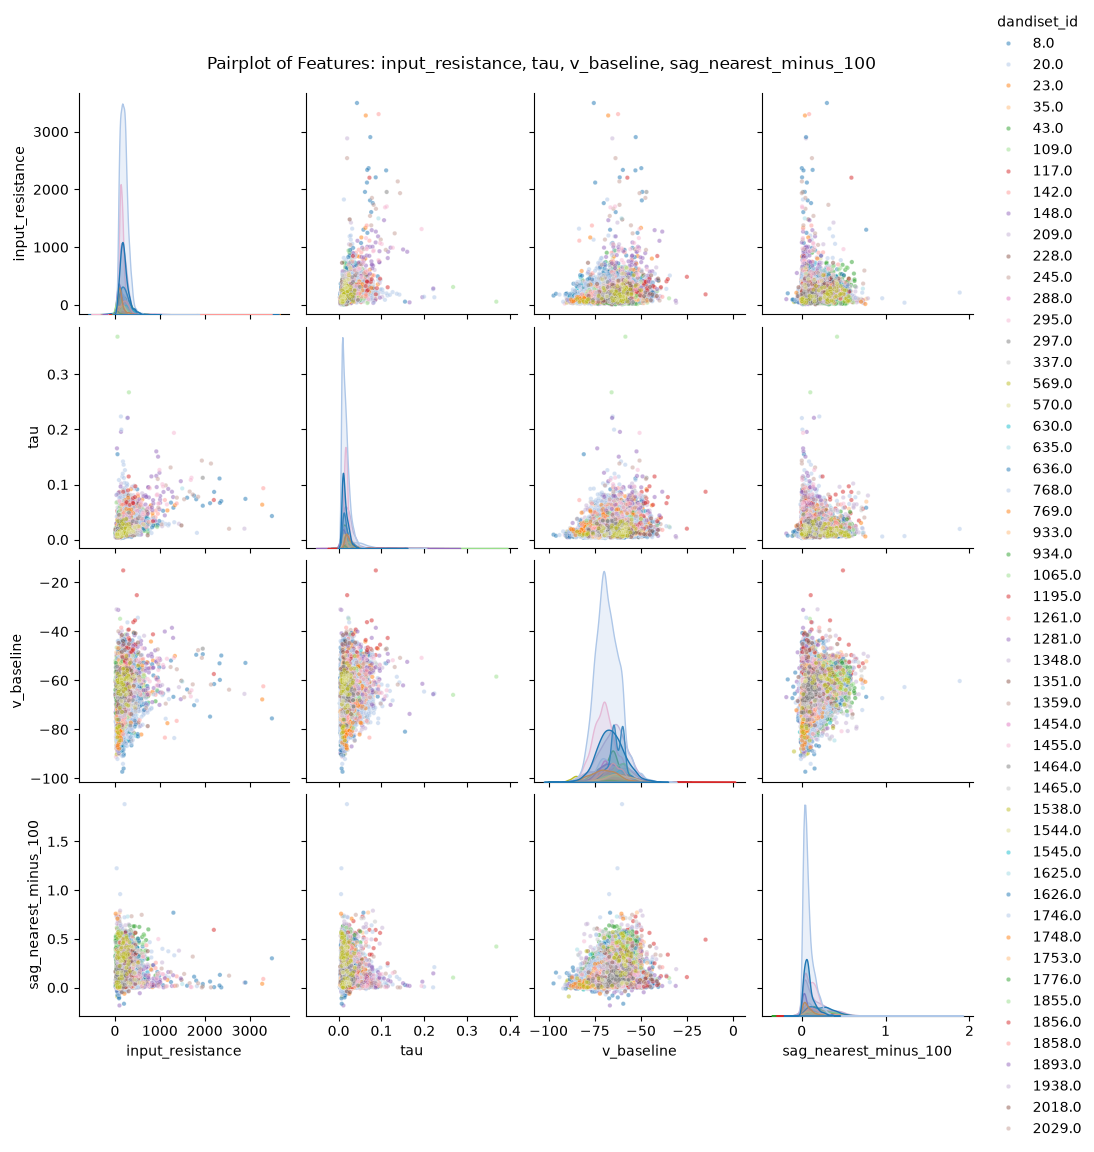

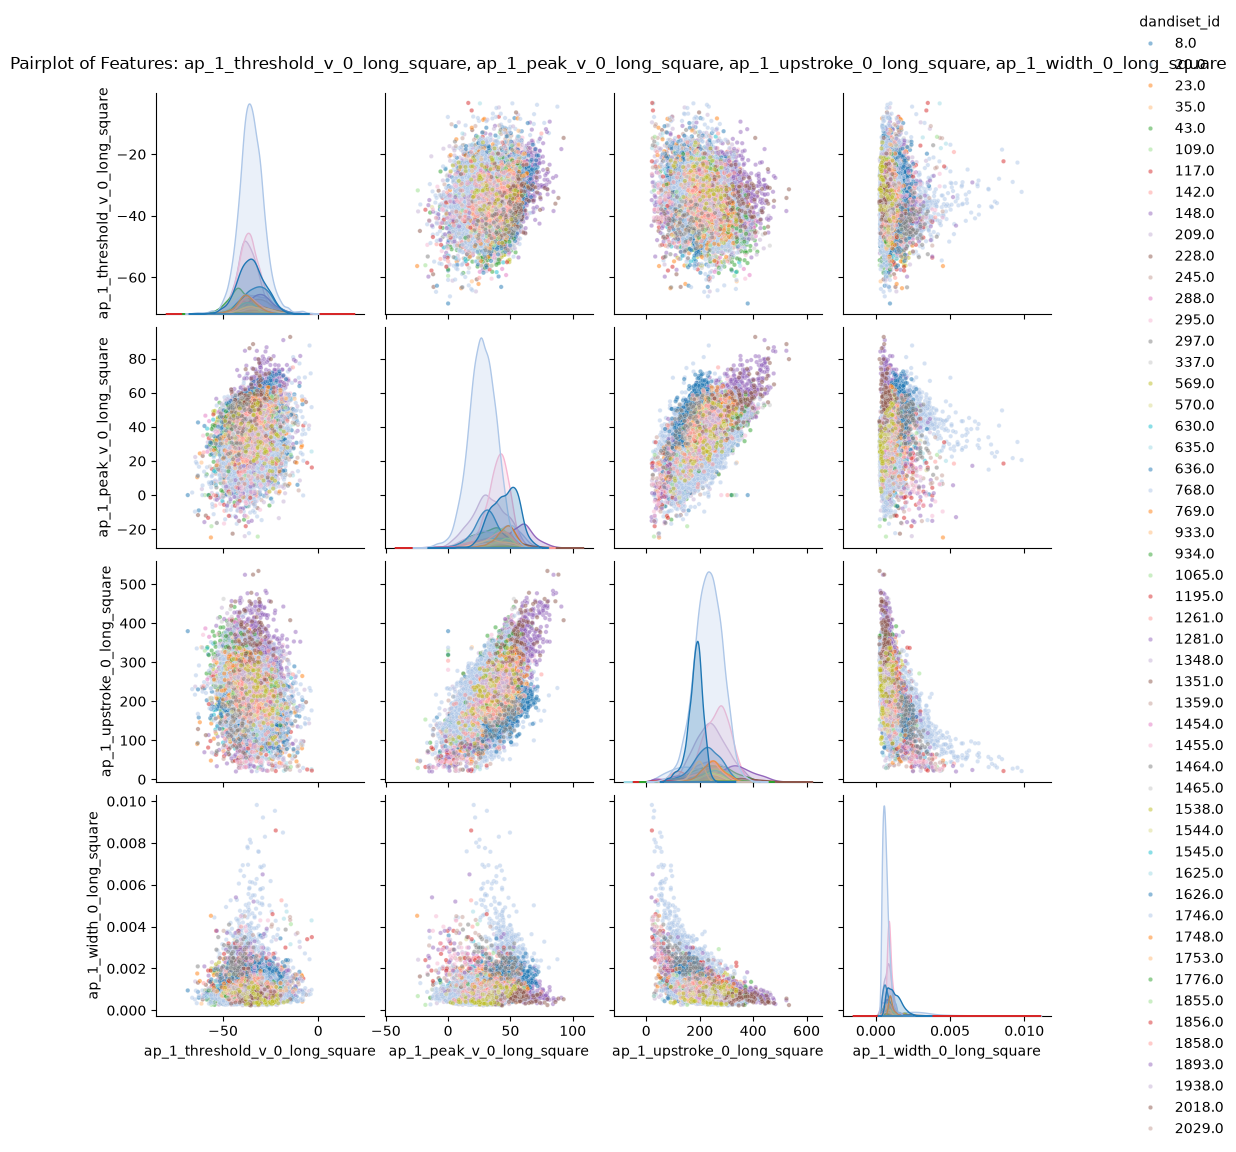

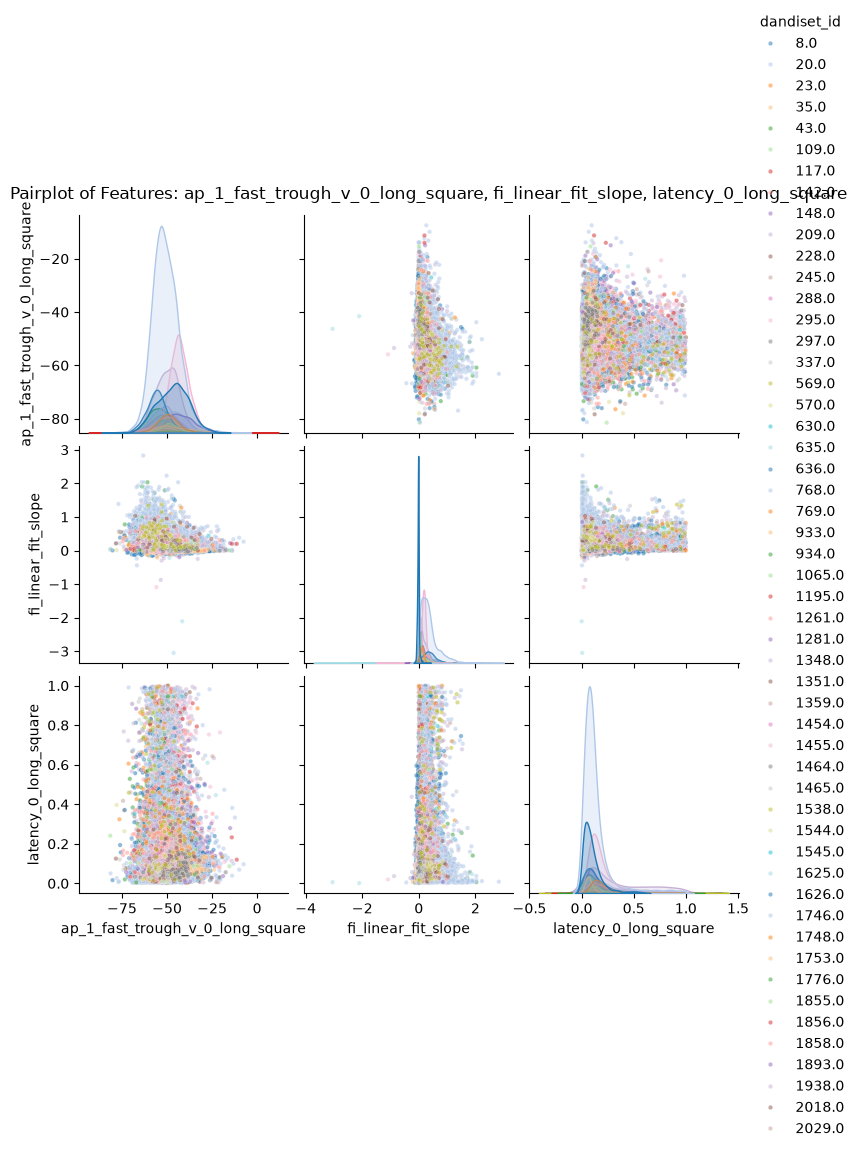

In [10]:
from dandi_scraper.config import QC_FEATURE_BOUNDS

def quick_qc(df, qc_features=QC_FEATURE_BOUNDS):
    #this is a quick qc function to check if the data is good, applied when merging the dandisets
    for feature, (min_val, max_val) in qc_features.items():
        if feature in df.columns:
            #get number of failing values for logging
            _failing = df[(df[feature] < min_val) | (df[feature] > max_val)]
            num_failing = len(_failing)
            print(f"QC: {num_failing} cells failed {feature} check ({min_val} to {max_val}), examples:\n {_failing[feature].head()}")
            df = df[(df[feature] >= min_val) & (df[feature] <= max_val)]
    return df

#run 4 pairplots for some features
for i in range(0, len(features_used), 4):
    subset = features_used[i:i+4]
    sns.pairplot(data, vars=subset, hue='dandiset_id', palette='tab20', diag_kind='kde', plot_kws={'alpha':0.5, 's':10})
    plt.suptitle(f'Pairplot of Features: {", ".join(subset)}', y=1.02)
    plt.show()

## Part 4: Building the map

Finally, the dandisets are merged into one table and embedded:

1. Drop cells that fail the QC bounds above, cells missing more than half of the features used for the map, and duplicate cells.
2. Fill in the remaining missing values with a KNN imputer (within each dandiset), and clip each feature to its 0.5 - 99.5th percentile.
3. Log-scale the skewed features (Rin, tau, AP width and upstroke), then robust-scale everything and clip at ±5 IQRs, so no single feature can dominate.
4. Run UMAP on the result.

The map uses 11 features: input resistance, tau, baseline voltage, sag, the first spike's threshold, peak, upstroke, width and fast trough, the f-I slope, and the latency to first spike. I originally also used the mean AP features and the firing rate at rheobase, but dropped them. The mean AP features correlate almost perfectly with the first AP versions (so keeping both double-weights spike shape), and the firing rate at rheobase is mostly just 1/(step duration) (see above).